# Churn em telecom: quem vale a pena tentar reter?

**Pergunta de negócio:** a operadora tem verba para uma campanha de retenção. Quais clientes abordar para que a campanha dê lucro, e não só "acerte" quem vai sair?

**Dados:** [Telco Customer Churn](https://github.com/IBM/telco-customer-churn-on-icp4d) (IBM, licença Apache 2.0): 7.043 clientes de uma operadora fictícia, com contrato, serviços, forma de pagamento, mensalidade e se cancelaram no último mês.

**Roteiro**
1. Preparação dos dados
2. Quem sai e quando: taxas de churn e análise de sobrevivência
3. Modelos: regressão logística × gradient boosting, com probabilidades calibradas
4. Decisão: curva de lucro da campanha e sensibilidade às premissas
5. Limitações

In [1]:
# Bibliotecas e funções do projeto
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sys.path.insert(0, "..")  # pasta raiz do repositório, para importar o estilo compartilhado
from comum.estilo import COR, aplicar, br, fonte, subtitulo
import churn as ch

warnings.filterwarnings("ignore")
aplicar()
FONTE = "Fonte: IBM Telco Customer Churn · elaboração: Cézar Bento"
SEMENTE = 42

## 1. Preparação dos dados

In [2]:
dados = ch.carregar()
print(f"{len(dados):,} clientes · taxa de churn: {br(dados.churn.mean() * 100, 1)}%".replace(",", ".", 1))
print(f"Valores ausentes após a correção de TotalCharges: {dados.isna().sum().sum()}")
print(dados.head(3).T.to_string())

7.043 clientes · taxa de churn: 26,5%
Valores ausentes após a correção de TotalCharges: 0
                                 0             1               2
customerID              7590-VHVEG    5575-GNVDE      3668-QPYBK
gender                      Female          Male            Male
SeniorCitizen                    0             0               0
Partner                        Yes            No              No
Dependents                      No            No              No
tenure                           1            34               2
PhoneService                    No           Yes             Yes
MultipleLines     No phone service            No              No
InternetService                DSL           DSL             DSL
OnlineSecurity                  No           Yes             Yes
OnlineBackup                   Yes            No             Yes
DeviceProtection                No           Yes              No
TechSupport                     No            No              No


In [3]:
# Variáveis do modelo. O identificador do cliente fica de fora: não carrega informação sobre o comportamento
# e só faria o modelo decorar clientes.
NUMERICAS = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]
CATEGORICAS = [c for c in dados.columns if c not in NUMERICAS + ["customerID", "churn"]]
X, y = dados[NUMERICAS + CATEGORICAS], dados["churn"]

# Separação estratificada: 25% dos clientes ficam guardados para a avaliação final e para a curva de lucro.
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEMENTE)
print(f"Treino: {len(X_treino):,} · Teste: {len(X_teste):,}".replace(",", "."))

Treino: 5.282 · Teste: 1.761


## 2. Quem sai e quando

### 2.1 O contrato explica quase tudo
O contrato mensal tem churn de 43%; o de dois anos, 3%. Fibra óptica e boleto eletrônico também concentram saídas.

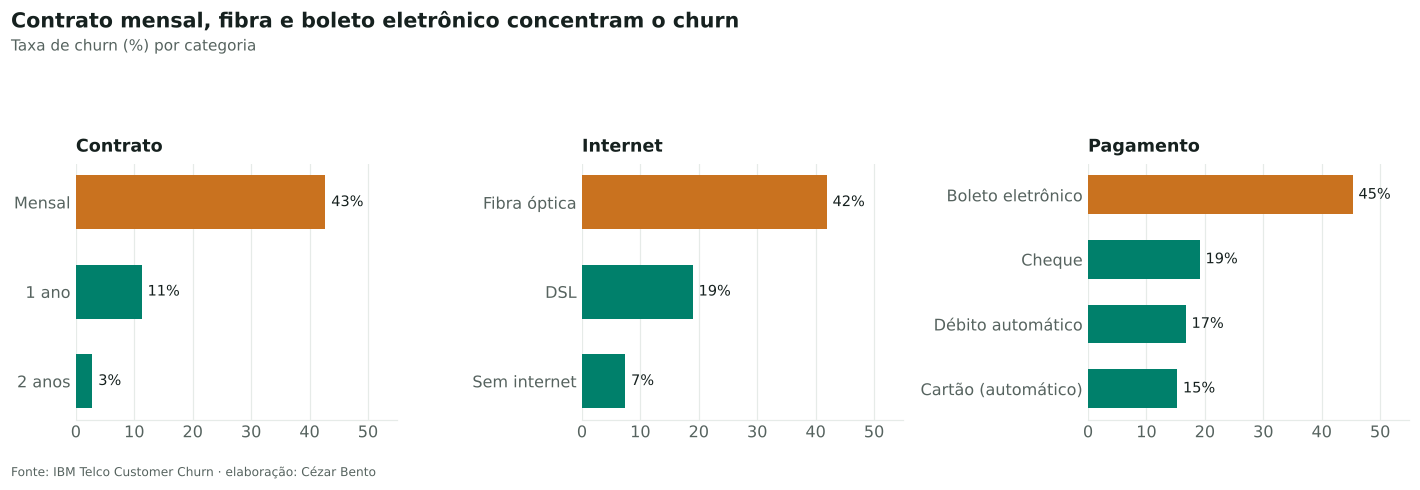

In [4]:
def taxa_por(coluna):
    return dados.groupby(coluna).churn.mean().sort_values()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
traducao = {"Month-to-month": "Mensal", "One year": "1 ano", "Two year": "2 anos",
            "Fiber optic": "Fibra óptica", "No": "Sem internet", "DSL": "DSL",
            "Electronic check": "Boleto eletrônico", "Mailed check": "Cheque",
            "Bank transfer (automatic)": "Débito automático", "Credit card (automatic)": "Cartão (automático)"}
for ax, (coluna, titulo) in zip(axes, [("Contract", "Contrato"), ("InternetService", "Internet"),
                                       ("PaymentMethod", "Pagamento")]):
    t = taxa_por(coluna)
    cores = [COR["destaque"] if v == t.max() else COR["principal"] for v in t]
    ax.barh([traducao.get(i, i) for i in t.index], t * 100, color=cores, height=0.6)
    for i, v in enumerate(t):
        ax.text(v * 100 + 1, i, f"{br(v * 100)}%", va="center", fontsize=9.5, color=COR["texto"])
    ax.set_xlim(0, 55); ax.grid(axis="y", visible=False); ax.set_title(titulo, fontsize=11.5, pad=8)
fig.suptitle("Contrato mensal, fibra e boleto eletrônico concentram o churn", x=0.01, ha="left",
             fontsize=13.5, fontweight="bold", color=COR["texto"], y=1.13)
fig.text(0.01, 1.03, "Taxa de churn (%) por categoria", fontsize=10, color=COR["texto2"])
fig.tight_layout(rect=(0, 0, 1, 0.95)); fonte(fig, FONTE)
fig.savefig("figuras/01_taxas.png")

### 2.2 Análise de sobrevivência: o risco está no começo
A curva de Kaplan-Meier mostra a fração de clientes que continua ativa após *n* meses. Ela trata corretamente quem ainda é cliente (dado "censurado": sabemos que ficou até hoje, não quando vai sair). No contrato mensal, metade dos clientes sai antes de completar três anos; quase toda a perda acontece nos primeiros meses.

Mediana de permanência (meses): {'Mensal': 35, '1 ano': None, '2 anos': None}


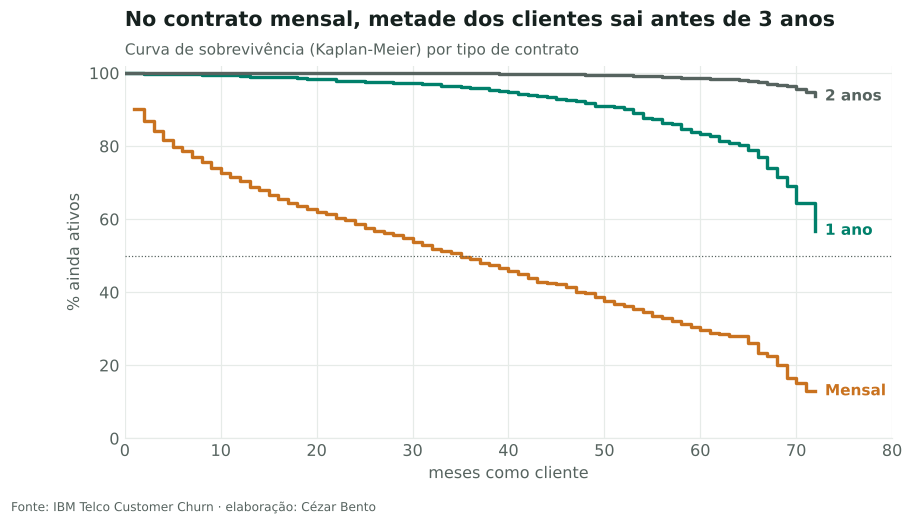

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.4))
cores = {"Month-to-month": COR["destaque"], "One year": COR["principal"], "Two year": COR["texto2"]}
nomes = {"Month-to-month": "Mensal", "One year": "1 ano", "Two year": "2 anos"}
medianas = {}
for contrato, grupo in dados.groupby("Contract"):
    km = ch.kaplan_meier(grupo.tenure, grupo.churn)
    ax.step(km.meses, km.sobrevivencia * 100, where="post", color=cores[contrato], lw=2.2)
    ax.text(km.meses.iloc[-1] + 1, km.sobrevivencia.iloc[-1] * 100, nomes[contrato],
            va="center", fontsize=10, color=cores[contrato], fontweight="bold")
    abaixo = km[km.sobrevivencia <= 0.5]
    medianas[nomes[contrato]] = int(abaixo.meses.iloc[0]) if len(abaixo) else None
ax.axhline(50, color=COR["texto2"], lw=0.8, ls=":")
ax.set_ylim(0, 102); ax.set_xlim(0, 80); ax.set_xlabel("meses como cliente"); ax.set_ylabel("% ainda ativos")
ax.set_title("No contrato mensal, metade dos clientes sai antes de 3 anos")
subtitulo(ax, "Curva de sobrevivência (Kaplan-Meier) por tipo de contrato")
fonte(fig, FONTE)
fig.savefig("figuras/02_sobrevivencia.png")
print("Mediana de permanência (meses):", medianas)

## 3. Modelos

Comparo um modelo interpretável (regressão logística) com um modelo mais flexível (gradient boosting). O critério principal é **PR-AUC**, que mede a qualidade do ranking dos clientes que de fato saem: é o ranking que a campanha vai usar. ROC-AUC e Brier (erro das probabilidades) completam a avaliação.

In [6]:
preparo = ColumnTransformer([
    ("num", StandardScaler(), NUMERICAS),
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), CATEGORICAS),
])
modelos = {
    "Regressão logística": Pipeline([("prep", preparo), ("clf", LogisticRegression(max_iter=2000, C=0.5))]),
    "Gradient boosting": Pipeline([("prep", preparo), ("clf", HistGradientBoostingClassifier(
        max_iter=300, learning_rate=0.04, max_leaf_nodes=15, l2_regularization=1.0, random_state=SEMENTE))]),
}

# Validação cruzada estratificada (5 dobras) apenas no treino
cv = StratifiedKFold(5, shuffle=True, random_state=SEMENTE)
for nome, modelo in modelos.items():
    pr = cross_val_score(modelo, X_treino, y_treino, cv=cv, scoring="average_precision")
    print(f"{nome:22s} PR-AUC na validação cruzada: {pr.mean():.3f} ± {pr.std():.3f}")

Regressão logística    PR-AUC na validação cruzada: 0.661 ± 0.037
Gradient boosting      PR-AUC na validação cruzada: 0.661 ± 0.029


In [7]:
# Avaliação final no conjunto de teste, que nenhum modelo viu
resultados, probs = [], {}
for nome, modelo in modelos.items():
    modelo.fit(X_treino, y_treino)
    p = modelo.predict_proba(X_teste)[:, 1]
    probs[nome] = p
    resultados.append({"modelo": nome, "ROC-AUC": roc_auc_score(y_teste, p),
                       "PR-AUC": average_precision_score(y_teste, p), "Brier": brier_score_loss(y_teste, p)})
print(pd.DataFrame(resultados).set_index("modelo").round(3).to_string())
print(f"\nReferência: PR-AUC de um ranking aleatório = taxa de churn = {y_teste.mean():.3f}")

                     ROC-AUC  PR-AUC  Brier
modelo                                     
Regressão logística    0.847   0.638  0.136
Gradient boosting      0.841   0.644  0.137

Referência: PR-AUC de um ranking aleatório = taxa de churn = 0.265


**Leitura:** os dois modelos empatam — a relação entre as variáveis e o churn é quase aditiva, e a regressão logística já a captura. Com desempenho igual, fico com a **regressão logística**: é mais simples de explicar para a área de negócio e de manter. As probabilidades dela estão bem calibradas (gráfico abaixo), o que importa porque a decisão usa a probabilidade, não só a ordem.

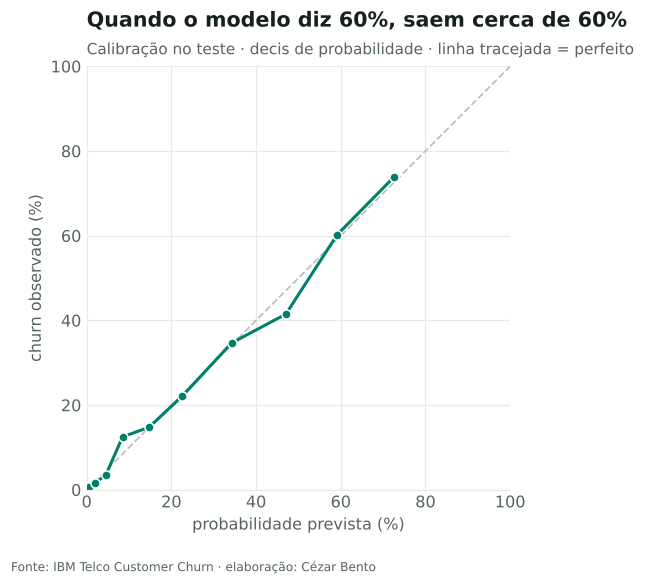

In [8]:
p_final = probs["Regressão logística"]
frac_real, prob_media = calibration_curve(y_teste, p_final, n_bins=10, strategy="quantile")
fig, ax = plt.subplots(figsize=(5.2, 5))
ax.plot([0, 100], [0, 100], color=COR["contexto"], lw=1.2, ls="--")
ax.plot(prob_media * 100, frac_real * 100, color=COR["principal"], lw=2, marker="o", ms=6, markeredgecolor="white")
ax.set_xlabel("probabilidade prevista (%)"); ax.set_ylabel("churn observado (%)")
ax.set_xlim(0, 100); ax.set_ylim(0, 100); ax.set_aspect("equal")
ax.set_title("Quando o modelo diz 60%, saem cerca de 60%")
subtitulo(ax, "Calibração no teste · decis de probabilidade · linha tracejada = perfeito")
fonte(fig, FONTE)
fig.savefig("figuras/03_calibracao.png")

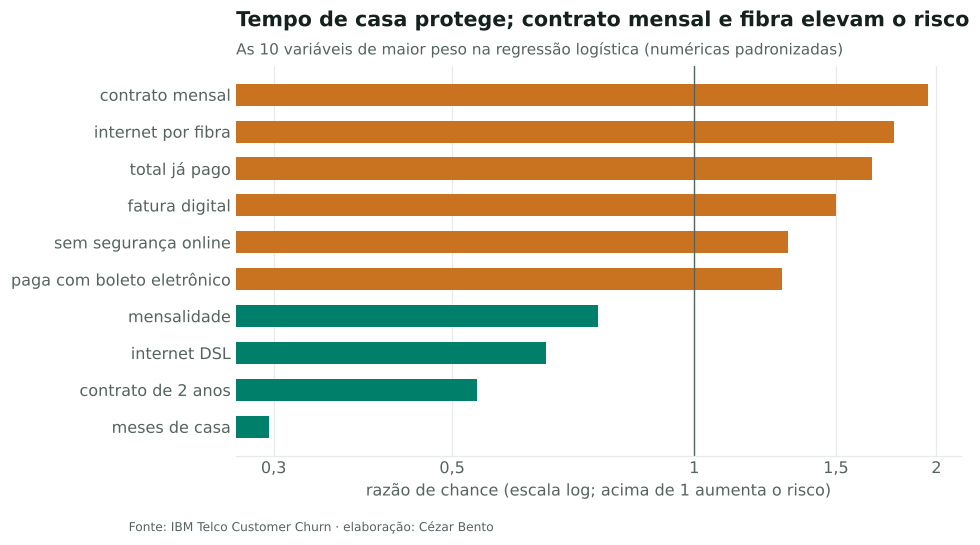

In [9]:
# O que o modelo aprendeu: razões de chance (odds ratios) das variáveis mais fortes
logit = modelos["Regressão logística"]
nomes_var = logit.named_steps["prep"].get_feature_names_out()
coef = pd.Series(logit.named_steps["clf"].coef_[0], index=nomes_var)
top = coef.reindex(coef.abs().sort_values(ascending=False).index[:10]).sort_values()
NOMES_PT = {"tenure": "meses de casa", "MonthlyCharges": "mensalidade", "TotalCharges": "total já pago",
            "Contract_Month-to-month": "contrato mensal", "Contract_Two year": "contrato de 2 anos",
            "Contract_One year": "contrato de 1 ano", "InternetService_Fiber optic": "internet por fibra",
            "InternetService_DSL": "internet DSL", "PaperlessBilling_Yes": "fatura digital",
            "OnlineSecurity_No": "sem segurança online", "PaymentMethod_Electronic check": "paga com boleto eletrônico",
            "TechSupport_No": "sem suporte técnico", "SeniorCitizen": "idoso"}
rotulos = {n: NOMES_PT.get(n.split("__")[1], n.split("__")[1]) for n in top.index}

fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.barh([rotulos[n] for n in top.index], np.exp(top.values),
        color=[COR["destaque"] if v > 0 else COR["principal"] for v in top.values], height=0.6, left=0)
ax.axvline(1, color=COR["texto2"], lw=0.9)
ax.set_xscale("log")
ax.set_xticks([0.3, 0.5, 1, 1.5, 2], ["0,3", "0,5", "1", "1,5", "2"]); ax.minorticks_off()
ax.set_xlabel("razão de chance (escala log; acima de 1 aumenta o risco)")
ax.grid(axis="y", visible=False)
ax.set_title("Tempo de casa protege; contrato mensal e fibra elevam o risco")
subtitulo(ax, "As 10 variáveis de maior peso na regressão logística (numéricas padronizadas)")
fonte(fig, FONTE)
fig.savefig("figuras/04_razoes_chance.png")

**Cuidado ao ler os coeficientes:** meses de casa, mensalidade e total já pago são fortemente correlacionados (total ≈ meses × mensalidade). Por isso "total já pago" aparece aumentando o risco: com o tempo de casa fixo, um total maior indica mensalidade recente mais alta. Os três devem ser lidos juntos, e o modelo serve para **ordenar clientes**, não para estimar efeitos causais.

## 4. Decisão: quem abordar

Acertar quem vai sair não basta: abordar um cliente custa dinheiro, e um cliente que paga pouco pode não compensar o custo. **Premissas** (explícitas para serem discutidas com a área de negócio):

| Premissa | Valor |
|---|---|
| Custo por cliente abordado (incentivo + operação) | US$ 50 |
| Fração dos que iriam sair e ficam após a oferta | 30% |
| Receita preservada por cliente retido | 12 meses de mensalidade |

Ganho esperado de abordar um cliente = P(sair) × 30% × 12 × mensalidade − 50. A curva abaixo mostra o lucro **realizado no conjunto de teste** ao abordar os clientes em ordem de pontuação.

In [10]:
saiu = y_teste.values
mensal = X_teste["MonthlyCharges"].values
ev = ch.valor_esperado(p_final, mensal)
rng = np.random.default_rng(SEMENTE)

curvas = {
    "Ordenar por valor esperado": ch.curva_lucro(saiu, mensal, ev),
    "Ordenar só por probabilidade": ch.curva_lucro(saiu, mensal, p_final),
    "Ordem aleatória": ch.curva_lucro(saiu, mensal, rng.random(len(saiu))),
}
estrategias = {
    "Ninguém": 0.0,
    "Todos": ch.lucro_realizado(saiu, mensal, np.ones_like(saiu)),
    "Valor esperado > 0": ch.lucro_realizado(saiu, mensal, (ev > 0).astype(int)),
}
melhor = curvas["Ordenar por valor esperado"].loc[curvas["Ordenar por valor esperado"].lucro.idxmax()]
print(pd.Series(estrategias).map(lambda v: f"US$ {br(v)}").to_string())
print(f"\nRegra 'valor esperado > 0' aborda {(ev > 0).mean():.0%} da base de teste.")
print(f"Máximo da curva: US$ {br(melhor.lucro)} abordando {br(melhor.pct_abordados)}% da base.")

Ninguém                    US$ 0
Todos                 US$ 35.485
Valor esperado > 0    US$ 69.075

Regra 'valor esperado > 0' aborda 45% da base de teste.
Máximo da curva: US$ 69.125 abordando 45% da base.


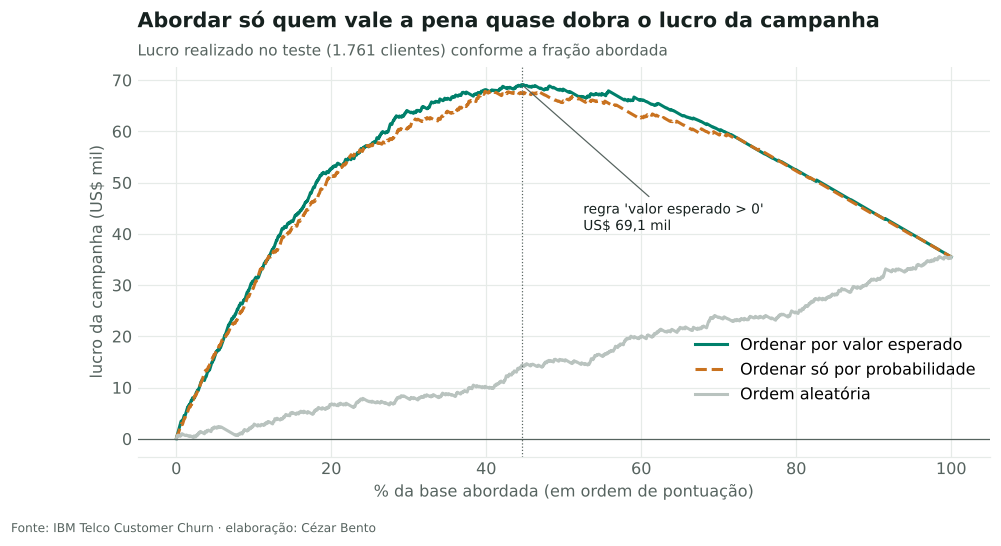

In [11]:
fig, ax = plt.subplots(figsize=(10, 4.6))
estilo = {"Ordenar por valor esperado": (COR["principal"], "-"), "Ordenar só por probabilidade": (COR["destaque"], "--"),
          "Ordem aleatória": (COR["contexto"], "-")}
for nome, c in curvas.items():
    cor, ls = estilo[nome]
    ax.plot(c.pct_abordados, c.lucro / 1000, color=cor, ls=ls, lw=2, label=nome)
x_ev = (ev > 0).mean() * 100
ax.axvline(x_ev, color=COR["texto2"], lw=0.8, ls=":")
ax.annotate(f"regra 'valor esperado > 0'\nUS$ {br(estrategias['Valor esperado > 0'] / 1000, 1)} mil",
            (x_ev, estrategias["Valor esperado > 0"] / 1000), xytext=(40, -95), textcoords="offset points",
            fontsize=9, color=COR["texto"], arrowprops=dict(arrowstyle="-", color=COR["texto2"], lw=0.8))
ax.axhline(0, color=COR["texto2"], lw=0.8)
ax.set_xlabel("% da base abordada (em ordem de pontuação)"); ax.set_ylabel("lucro da campanha (US$ mil)")
ax.legend(loc="lower right", bbox_to_anchor=(1, 0.1))
ax.set_title("Abordar só quem vale a pena quase dobra o lucro da campanha")
subtitulo(ax, f"Lucro realizado no teste ({br(len(saiu))} clientes) conforme a fração abordada")
fonte(fig, FONTE)
fig.savefig("figuras/05_curva_lucro.png")

### 4.1 E se as premissas estiverem erradas?
A taxa de sucesso da oferta é a premissa mais incerta. Recalculo a regra para 15%, 30% e 45%.

In [12]:
linhas = []
for sucesso in [0.15, 0.30, 0.45]:
    ch.TAXA_SUCESSO = sucesso
    ev_s = ch.valor_esperado(p_final, mensal)
    alvo = (ev_s > 0).astype(int)
    linhas.append({"taxa de sucesso": f"{sucesso:.0%}", "% abordados": f"{alvo.mean():.0%}",
                   "lucro com a regra (US$)": br(ch.lucro_realizado(saiu, mensal, alvo)),
                   "lucro abordando todos (US$)": br(ch.lucro_realizado(saiu, mensal, np.ones_like(saiu)))})
ch.TAXA_SUCESSO = 0.30  # volta à premissa base
print(pd.DataFrame(linhas).to_string(index=False))

taxa de sucesso % abordados lucro com a regra (US$) lucro abordando todos (US$)
            15%         30%                  18.536                     -26.282
            30%         45%                  69.075                      35.485
            45%         53%                 123.170                      97.253


**Recomendação:** abordar apenas os clientes com valor esperado positivo — 45% da base no cenário base. Com as premissas centrais, isso **quase dobra o lucro** em relação a abordar todos (US$ 69 mil contra US$ 35 mil no teste) e gasta menos da metade da verba. A regra se ajusta sozinha: se a oferta for menos eficaz (15%), ela aborda menos gente e continua lucrando, enquanto "abordar todos" passa a dar prejuízo.

## 5. Limitações
- **Base de exemplo:** a operadora é fictícia (dados da IBM) e o retrato é de um único mês; num caso real, a validação seria temporal (treinar no passado, testar no mês seguinte).
- **Premissas da campanha:** custo, taxa de sucesso e horizonte de receita precisam vir da área de negócio — idealmente medidos num **teste A/B** com grupo de controle.
- **Correlação, não causa:** o modelo indica quem tende a sair, não por quê. Que o contrato de dois anos "proteja" pode refletir quem escolhe esse contrato, e não o contrato em si.